In [1]:
from datascience import *
%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')
import numpy as np
import warnings
warnings.simplefilter(action='ignore', category=np.VisibleDeprecationWarning)

## Bootstrapping ##

## Total Compensation in Population 

In [2]:
sf = Table.read_table('san_francisco_2019.csv')
sf.show(3)

Organization Group,Department,Job Family,Job,Salary,Overtime,Benefits,Total Compensation
Public Protection,Adult Probation,Information Systems,IS Trainer-Journey,91332,0,40059,131391
Public Protection,Adult Probation,Information Systems,IS Engineer-Assistant,123241,0,49279,172520
Public Protection,Adult Probation,Information Systems,IS Business Analyst-Senior,115715,0,46752,162468


In [ ]:
# Who made the most money
sf.sort('Total Compensation', descending=True).show(5)

In [ ]:
# Who made the least money
sf.sort('Total Compensation', descending=False).show(5)

In [ ]:
# $15/hr, 20 hr/wk, 50 weeks

min_salary = 15 * 20 * 50
sf = sf.where('Salary', are.above(min_salary))

In [ ]:
sf.num_rows

/opt/homebrew/lib/python3.11/site-packages/datascience/tables.py:5865: UserWarning: FixedFormatter should only be used together with FixedLocator
  axis.set_xticklabels(ticks, rotation='vertical')


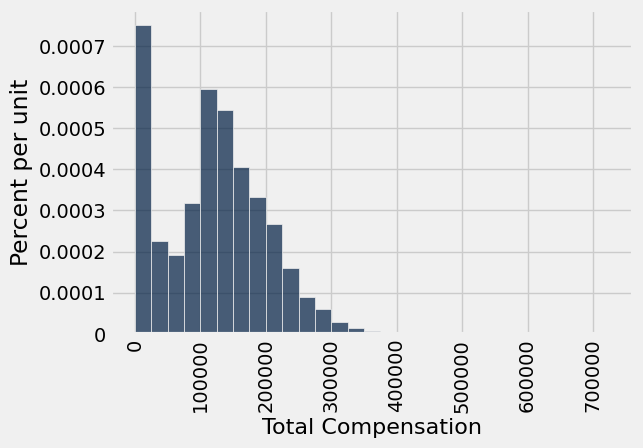

In [3]:
sf_bins = np.arange(0, 726000, 25000)
sf.hist('Total Compensation', bins=sf_bins)

## Parameter: Median Total Compensation 

In [4]:
pop_median = percentile(50, sf.column('Total Compensation'))
pop_median 

121630.0

## Estimating the Parameter (Pretend it is Unknown) 

In [8]:
our_sample = sf.sample(400, with_replacement=False)

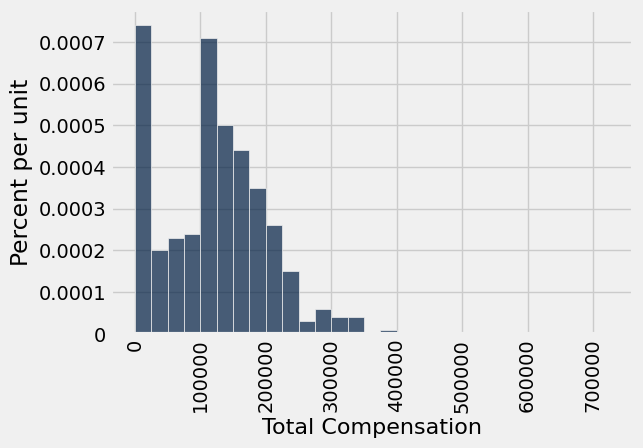

In [9]:
our_sample.hist('Total Compensation', bins=sf_bins)

In [10]:
percentile(50, our_sample.column('Total Compensation') )

119033.0

But in the real world we won't be able to keep going back to the population. How to generate a new random sample *without going back to the population?*

# Resampling

Sample randomly
 - from the original sample
 - with replacement
 - the same number of times as the original sample size

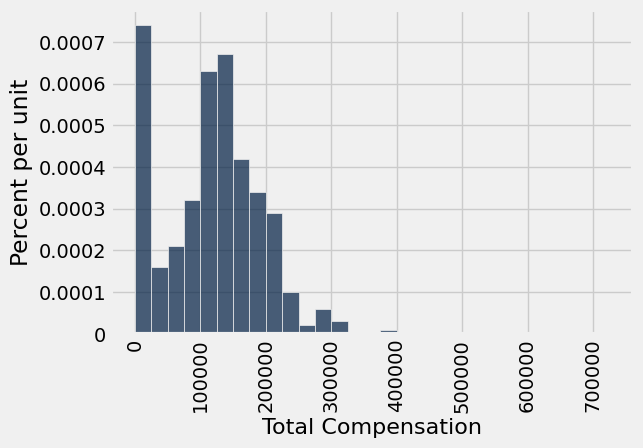

In [17]:
# Default behavior of tbl.sample:
# at random with replacement,
# the same number of times as rows of tbl

bootstrap_sample = our_sample.sample()
bootstrap_sample.hist('Total Compensation', bins=sf_bins)

## Question: Run the above block of code several times. How similar are the distributions? ##

In [18]:
percentile(50, bootstrap_sample.column('Total Compensation'))

122414.0

In [21]:
def one_bootstrap_median():
    # draw the bootstrap sample
    resample = our_sample.sample()
    # return the median total compensation in the bootstrap sample
    return percentile(50, resample.column('Total Compensation'))

In [29]:
one_bootstrap_median()

112689.0

In [30]:
# Generate the medians of 1000 bootstrap samples
num_repetitions = 1000
bstrap_medians = make_array()
for i in np.arange(num_repetitions):
    bstrap_medians = np.append(bstrap_medians, one_bootstrap_median())

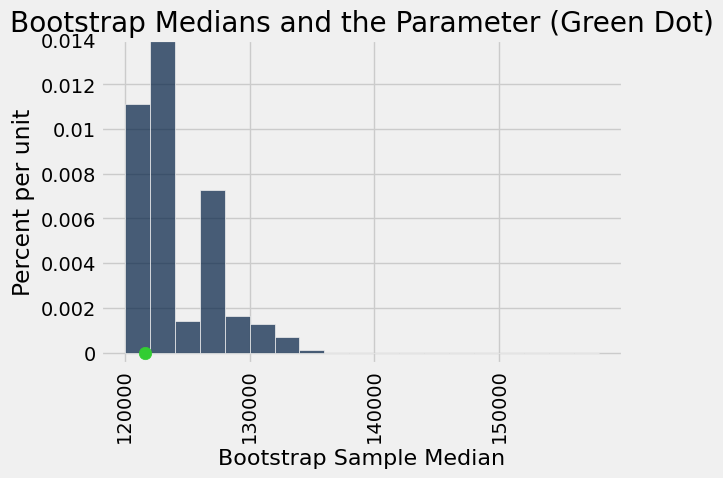

In [31]:
resampled_medians = Table().with_column('Bootstrap Sample Median', bstrap_medians)
median_bins=np.arange(120000, 160000, 2000)
resampled_medians.hist(bins = median_bins)

# Plotting parameters; you can ignore this code
parameter_green = '#32CD32'
plots.ylim(-0.000005, 0.00014)
plots.scatter(pop_median, 0, color=parameter_green, s=80, zorder=2)
plots.title('Bootstrap Medians and the Parameter (Green Dot)');

## Percentile Method: Middle 95% of the Bootstrap Estimates 

In [ ]:
left = percentile(2.5, bstrap_medians)
right = percentile(97.5, bstrap_medians)

make_array(left, right)

In [ ]:
resampled_medians.hist(bins = median_bins)

# Plotting parameters; you can ignore this code
plots.ylim(-0.000005, 0.00014)
plots.plot(make_array(left, right), make_array(0, 0), color='yellow', lw=3, zorder=1)
plots.scatter(pop_median, 0, color=parameter_green, s=40, zorder=2);